# Saving and loading models

**Run this notebook:** in Colab, choose **Runtime → Run all**. The first cell prepares METIS automatically using uv; a fresh runtime needs this setup again. These short tutorials use a CPU. Locally, select your [METIS Python environment](https://ojwatson.github.io/metis/basics/installing_metis.html).

The outputs below were generated when the documentation was built. [Source revision `0533e26bcabc`](https://github.com/OJWatson/metis/tree/0533e26bcabc75285429cda8181f1c8489e861ef).

In [ ]:
#@title Prepare METIS (run once per runtime)
"""Embedded in notebook downloads: prepare their disposable Colab runtime with uv."""

import importlib
import importlib.metadata
import importlib.util
import io
import json
import os
from pathlib import Path
import platform
import re
import shutil
import subprocess
import sys
import tarfile
import urllib.request


UV_VERSION = "0.7.22"
INSTALL_GUIDE = "https://ojwatson.github.io/metis/basics/installing_metis.html"


def _installed_version(package):
    try:
        return importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        return None


def _compatible_pin(package, minimum, maximum=None):
    """Preserve compatible binary libraries already supplied by Colab."""
    version = _installed_version(package)
    if version is None:
        return None
    match = re.match(r"^(\d+)\.(\d+)(?:\.(\d+))?", version)
    if match is None:
        return None
    release = tuple(int(value or 0) for value in match.groups())
    if release < minimum or (maximum is not None and release >= maximum):
        return None
    return f"{package}=={version}"


def _uv_executable(directory):
    installed = shutil.which("uv")
    if installed:
        return installed
    destination = directory / "uv"
    if not destination.exists():
        architecture = {"x86_64": "x86_64", "aarch64": "aarch64"}.get(platform.machine())
        if architecture is None:
            raise RuntimeError(f"Unsupported Colab CPU architecture: {platform.machine()}")
        archive_name = f"uv-{architecture}-unknown-linux-gnu"
        url = (
            f"https://github.com/astral-sh/uv/releases/download/{UV_VERSION}/"
            f"{archive_name}.tar.gz"
        )
        with urllib.request.urlopen(url, timeout=120) as response:
            archive_bytes = response.read()
        with tarfile.open(fileobj=io.BytesIO(archive_bytes), mode="r:gz") as archive:
            # Read one known member, without extracting arbitrary archive paths.
            binary = archive.extractfile(f"{archive_name}/uv")
            if binary is None:
                raise RuntimeError("The uv release archive contains no executable")
            destination.write_bytes(binary.read())
        destination.chmod(0o755)
    return str(destination)


def _project_text(revision):
    dependencies = [
        f"metis-surrogate[plots,pandas] @ git+https://github.com/OJWatson/metis.git@{revision}",
        "torch==2.10.0",
    ]
    for package, minimum, maximum in [
        ("numpy", (2, 0, 0), (3, 0, 0)),
        ("matplotlib", (3, 9, 0), (4, 0, 0)),
        ("pandas", (2, 2, 0), (4, 0, 0)),
        ("pyarrow", (18, 0, 0), None),
        ("polars", (1, 37, 0), (3, 0, 0)),
    ]:
        pin = _compatible_pin(package, minimum, maximum)
        if pin:
            dependencies.append(pin)
    return (
        '[project]\nname = "metis-colab-tutorial"\nversion = "0.0.0"\n'
        f'requires-python = ">={sys.version_info.major}.{sys.version_info.minor},'
        f'<{sys.version_info.major}.{sys.version_info.minor + 1}"\n'
        f"dependencies = {json.dumps(dependencies)}\n\n"
        '[tool.uv]\npackage = false\n\n'
        '[tool.uv.sources]\ntorch = { index = "pytorch-cpu" }\n\n'
        '[[tool.uv.index]]\nname = "pytorch-cpu"\n'
        'url = "https://download.pytorch.org/whl/cpu"\nexplicit = true\n'
    )


def _metis_origin():
    try:
        return importlib.metadata.distribution("metis-surrogate").read_text("direct_url.json")
    except importlib.metadata.PackageNotFoundError:
        return None


def prepare_colab(revision):
    """Install only inside Colab; local notebooks use the selected METIS environment."""
    if not re.fullmatch(r"[a-f0-9]{40}", revision):
        raise ValueError("Notebook setup needs an exact 40-character source revision")
    try:
        in_colab = (
            importlib.util.find_spec("google.colab") is not None
            and bool(os.environ.get("COLAB_RELEASE_TAG") or os.environ.get("COLAB_BACKEND_VERSION"))
        )
    except ModuleNotFoundError:
        in_colab = False
    if not in_colab:
        if _installed_version("metis-surrogate") is None:
            raise RuntimeError(f"Select a Python environment containing METIS: {INSTALL_GUIDE}")
        print(f"Using local METIS {_installed_version('metis-surrogate')}.")
        return
    if sys.version_info < (3, 11):
        raise RuntimeError("This tutorial requires a Colab runtime with Python 3.11 or newer.")

    directory = Path("/content/.metis-notebooks")
    directory.mkdir(parents=True, exist_ok=True)
    (directory / "pyproject.toml").write_text(_project_text(revision), encoding="utf-8")
    loaded = {
        package: str(getattr(sys.modules[package], "__version__", _installed_version(package)))
        for package in ("numpy", "pandas", "torch", "matplotlib", "pyarrow", "polars")
        if package in sys.modules
    }
    metis_was_loaded = "metis" in sys.modules
    previous_metis_origin = _metis_origin()
    if metis_was_loaded:
        # Retain the import's identity if the user reruns setup after a restart
        # warning without actually restarting the Python process.
        previous_metis_origin = sys.modules["metis"].__dict__.setdefault(
            "_notebook_runtime_origin", previous_metis_origin,
        )
    environment = os.environ.copy()
    # Colab is a disposable runtime. Keep its unrelated packages and its active
    # notebook interpreter, instead of adding a second environment to sys.path.
    environment["UV_PROJECT_ENVIRONMENT"] = sys.prefix
    environment.pop("VIRTUAL_ENV", None)
    print("Preparing this Colab runtime with uv (CPU tutorial environment)…")
    result = subprocess.run(
        [_uv_executable(directory), "sync", "--inexact", "--no-dev", "--no-editable",
         "--project", str(directory), "--python", sys.executable],
        env=environment, text=True, capture_output=True,
    )
    if result.returncode:
        raise RuntimeError(f"METIS setup failed:\n{result.stdout}\n{result.stderr}")
    importlib.invalidate_caches()
    changed = [package for package, before in loaded.items() if _installed_version(package) != before]
    if metis_was_loaded and _metis_origin() != previous_metis_origin:
        changed.append("metis")
    if changed:
        raise RuntimeError(
            "Setup updated already-loaded libraries (" + ", ".join(changed) + "). "
            "Choose Runtime > Restart session, then Run all. Setup will reuse its installed packages."
        )
    print(f"METIS {_installed_version('metis-surrogate')} is ready. Continue with the tutorial.")


prepare_colab("0533e26bcabc75285429cda8181f1c8489e861ef")


Once trained, we'd like to use our surrogate in downstream applications: a
model fitting routine, a script exploring scenarios, or an interactive
dashboard. We may also want to resume training after an interruption. METIS
provides a saved surrogate for predictions and a training checkpoint for
continuing a fit.

## Saving a fitted surrogate

This page uses the MLP from the [training walkthrough](https://ojwatson.github.io/metis/basics/training.html). To make
the notebook runnable on its own, the setup below repeats that short SIRDS fit
if the saved model is not already present.

In [1]:
#| code-fold: true
#| code-summary: "Load the SIRDS example and prepare the MLP if needed"
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from metis import Surrogate, TrainingConfig, load_example

bank = load_example()
split = bank.split(seed=42)
if Path("sirds_surrogate.pt").exists():
    model = Surrogate.load("sirds_surrogate.pt")
else:
    model = Surrogate("mlp").fit(
        split.train, split.validation,
        config=TrainingConfig(steps=1000, batch_size=64, eval_every=100, seed=42),
    )

Save the fitted model with:

In [2]:
model.save("sirds_surrogate.pt")

PosixPath('sirds_surrogate.pt')

The file includes the model architecture, weights, input and output names,
time grid and fitted scalers. You can copy it to another computer with METIS
installed; the original simulations are not needed for prediction.

## Loading and making predictions

Load the model and supply named simulator inputs. Here we use one held-out
SIRDS setting so we can compare its prediction with the original simulations:

In [3]:
restored = Surrogate.load("sirds_surrogate.pt", device="cpu")
new_inputs = dict(zip(bank.input_names, split.test.inputs[0]))
prediction = restored.predict(new_inputs)
print("Prediction shape (settings, time points, outputs):", prediction.shape)
print("Outputs:", restored.output_names)
print("Same predictions after loading:", np.allclose(
    prediction, model.predict(new_inputs)
))

Prediction shape (settings, time points, outputs): (1, 40, 4)
Outputs: ('S_t', 'I_t', 'R_t', 'D_t')
Same predictions after loading: True


/home/runner/work/metis/metis/src/metis/surrogate.py:672: UserWarning: Inputs outside the training ranges for ['I_0']; predictions extrapolate and are not clipped.
  array = self._inputs(inputs)


The prediction is already in population counts, on the time grid used for
training. There is no need to rebuild the neural network or undo scaling.
As in the training walkthrough, METIS warns if a held-out input is beyond a
training range.

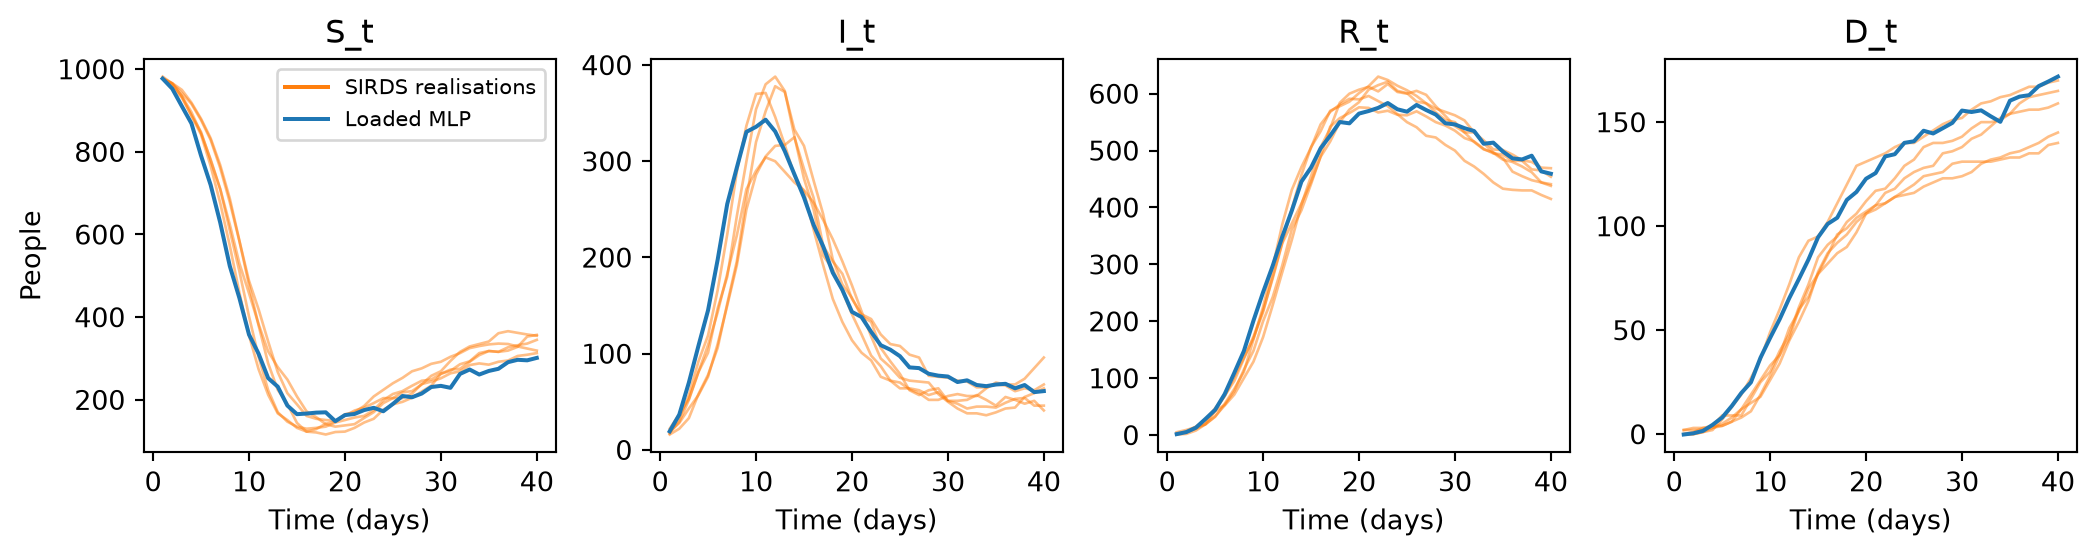

In [4]:
#| fig-cap: "Saved and reloaded MLP fitted on the bundled SIRDS training partition, compared with all five realisations at one test setting."
indices = [i for i, key in enumerate(split.test.group_keys)
           if key == split.test.group_keys[0]]
fig, axes = plt.subplots(1, 4, figsize=(11, 3), sharex=True)
for channel, (ax, name) in enumerate(zip(axes, bank.output_names)):
    ax.plot(bank.times, split.test.outputs[indices, :, channel].T,
            color="C1", alpha=0.5, linewidth=1)
    ax.plot([], [], color="C1", label="SIRDS realisations")
    ax.plot(restored.times, prediction[0, :, channel], color="C0", label="Loaded MLP")
    ax.set(title=name, xlabel="Time (days)")
axes[0].set_ylabel("People")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

*Saved and reloaded MLP fitted on the bundled SIRDS training partition, compared with all five realisations at one test setting.*

To make predictions for several scenarios at once, pass a data frame with the
same input column names:

In [5]:
scenarios = pd.DataFrame(split.test.inputs[::5], columns=bank.input_names)
trajectories = restored.predict(scenarios)
print(f"Predicted {len(trajectories)} SIRDS scenarios")

Predicted 20 SIRDS scenarios


/home/runner/work/metis/metis/src/metis/surrogate.py:672: UserWarning: Inputs outside the training ranges for ['I_0', 'gamma', 'omega', 'mu']; predictions extrapolate and are not clipped.
  array = self._inputs(inputs)


For a saved stochastic surrogate, use `sample(new_inputs, n_samples=100,
seed=42)` to generate multiple realisations. The result has shape
`(settings, samples, time points, outputs)`. These are the same methods you
would call inside a dashboard or a model fitting script.

## Checkpointing

For a longer training run, save checkpoints periodically so an interruption
does not lose all progress. The checkpoint contains optimizer and random
states as well as weights. In Python, set these fields in `TrainingConfig`:

```python
config = TrainingConfig(
    steps=10000,
    checkpoint_every=500,
    checkpoint_dir="checkpoints/sirds",
)
model = Surrogate("mlp").fit(split.train, split.validation, config=config)
```

To resume an interrupted run, repeat its settings and add `resume_from`:

```python
config = TrainingConfig(
    steps=10000,
    checkpoint_every=500,
    checkpoint_dir="checkpoints/sirds",
    resume_from="checkpoints/sirds/last.pt",
)
model = Surrogate("mlp").fit(split.train, split.validation, config=config)
```

`steps` is the original total, not a number of extra updates. Keep the same
bank, split, model and training settings; METIS checks them before continuing.
After training, call `model.save(...)` to create the file used for predictions.
A training checkpoint cannot be loaded with `Surrogate.load`.

The same options are available through Hydra:

```bash
uv run metis train \
  hydra.run.dir=outputs/sirds-training \
  training.steps=10000 \
  training.checkpoint_every=500 \
  training.checkpoint_dir=checkpoints/sirds
```

Hydra puts the relative checkpoint directory inside the run directory. To
resume from the same working directory, use the full path from there:

```bash
uv run metis train \
  hydra.run.dir=outputs/sirds-training \
  training.steps=10000 \
  training.checkpoint_every=500 \
  training.checkpoint_dir=checkpoints/sirds \
  training.resume_from=outputs/sirds-training/checkpoints/sirds/last.pt
```

See the [Hydra guide](https://ojwatson.github.io/metis/basics/hydra.html) for longer command-line workflows.